# Tutorial 7 — Foundation models and fine-tuning strategies

Excited-state data are expensive, so data sets are small. Ground-state foundation
models (MACE-MP, MACE-OFF, MACE-OMOL, MACE-MH-1, MACE-POLAR-1) have learned
chemistry from millions of structures. X-MACE can start from any of them: the
foundation becomes the **backbone**, and every electronic state starts on its
ground-state surface. This tutorial shows

1. how an excited-state model is built on a foundation, and that it starts exactly
   on the foundation's surface;
2. how different foundation models compare on the same small SO2 data set;
3. **fine-tuning strategies**: full fine-tuning, frozen layers, smaller learning
   rates for the backbone, LoRA, multi-head fine-tuning with replay (and
   pseudolabels), extra ground-state heads, the autoencoder, and state-specific
   electrostatics with MACE-POLAR-1;
4. how to take a model you already fine-tuned from a foundation and **fine-tune it
   further on additional data** (or transfer it to new states).

**Requirements:** `work/so2_train.xyz` and `work/so2_test.xyz` from Tutorial 2; an
internet connection for the first download of each foundation model (cached
afterwards in `~/.cache/mace`). Runtime: about an hour on 2 CPU cores (the large
foundations dominate; a few minutes on a GPU with `DEVICE = "cuda"`).

In [1]:
import re
import subprocess
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import ase.io
import matplotlib.pyplot as plt
import numpy as np
import torch

import mace  # noqa: F401
from mace.calculators import ExcitedMACECalculator
from mace.data.excited import soc_matrix_from_label
from mace.modules.spin_states import (
    same_multiplicity_pairs,
    soc_matrix_from_vectors,
    soc_vectors_from_matrix,
)

TUTORIAL = Path.cwd()
WORK = TUTORIAL / "work"
RUN = WORK / "foundations"
RUN.mkdir(parents=True, exist_ok=True)
DEVICE = "cpu"
plt.rcParams.update({"figure.dpi": 100})
assert (WORK / "so2_train.xyz").exists(), "run Tutorial 2 first"

## 1. A small data set

Foundation models matter most when data are scarce. We take **120** frames of the
SO2 training set (Tutorial 2) for fine-tuning, keep 240 more as "additional data"
for section 5, and test on the 150 test frames. The model predicts the same as in
Tutorial 3: 4 singlets and 3 triplets, NACs, spin–orbit couplings and dipoles.

In [2]:
frames = ase.io.read(WORK / "so2_train.xyz", ":")
rng = np.random.default_rng(0)
order = rng.permutation(len(frames))
small = [frames[i] for i in order[:120]]
extra = [frames[i] for i in order[120:360]]
ase.io.write(RUN / "small.xyz", small)
ase.io.write(RUN / "extra.xyz", extra)
test = ase.io.read(WORK / "so2_test.xyz", ":")
print(f"{len(small)} frames to fine-tune on, {len(extra)} more for later, {len(test)} test frames")

STATES = [4, 0, 3]
LABELS = ["--model=ExcitedMACE", "--states=4 0 3", "--compute_nacs", "--compute_socs",
          "--compute_dipoles"]
COMMON = [
    "--valid_fraction=0.15", "--batch_size=10", "--lr=0.005", "--seed=1",
    "--energy_weight=10", "--forces_weight=100", "--nacs_weight=10",
    "--socs_weight=1", "--dipoles_weight=1", f"--device={DEVICE}", "--default_dtype=float64",
]

120 frames to fine-tune on, 240 more for later, 150 test frames


## 2. What happens when you pass `--foundation_model`

The excited-state model has three parts:

| part | from the foundation? | role |
|---|---|---|
| **backbone** (embedding, interactions, products, its own readout, E0s, ZBL, electrostatics) | yes — all weights | ground-state energy E₀(R) and atomic features |
| **adapter layer** (one MACE interaction with l = 1 features) | new | equivariant features for NACs, SOCs, dipoles — also for scalar-only foundations |
| **state readouts** | new, energy readouts start at zero | E_s(R) = E₀(R) + correction_s(R) + n_atoms·shift_s, and all couplings |

So before any training, **every state is the foundation's ground state** (plus a
constant shift per state, fitted to the data). Let us check this with the Python API
on MACE-OFF23 (small): build the model on the foundation and compare with the
foundation itself.

In [3]:
import copy

from mace.calculators import mace_off
from mace.modules import ExcitedMACE, excited_head_layout
from mace.tools import torch_geometric
from mace import data

torch.set_default_dtype(torch.float64)  # the new parts are created in the default dtype
foundation = mace_off(model="small", device="cpu", default_dtype="float64").models[0]
print("foundation:", foundation.__class__.__name__, "| elements:", len(foundation.atomic_numbers),
      "| features:", foundation.products[-1].linear.irreps_out)

layout = excited_head_layout(7, states=STATES, compute_nacs=True, compute_socs=True,
                             soc_mode="spin_orbit", compute_dipoles=True)
xmace = ExcitedMACE(backbone=copy.deepcopy(foundation), head_layouts=[layout],
                    MLP_irreps="16x0e", adapter_irreps="16x0e + 16x1o")
print(f"X-MACE on it: {sum(p.numel() for p in xmace.parameters())} parameters "
      f"(foundation {sum(p.numel() for p in foundation.parameters())})")

z_table = mace.tools.AtomicNumberTable([int(z) for z in foundation.atomic_numbers])
configs = [data.config_from_atoms(a) for a in test[:3]]
batch = next(iter(torch_geometric.dataloader.DataLoader(
    [data.AtomicData.from_config(c, z_table=z_table, cutoff=float(foundation.r_max)) for c in configs],
    batch_size=3)))
e_states = xmace(batch.to_dict())["energy"].detach()
e_foundation = foundation(batch.clone().to_dict())["energy"].detach()
print("foundation energy:      ", e_foundation.numpy().round(4))
print("X-MACE, all 7 states:\n", e_states.numpy().round(4))

Using MACE-OFF23 MODEL for MACECalculator with /root/.cache/mace/MACE-OFF23_small.model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
foundation: ScaleShiftMACE | elements: 10 | features: 96x0e


X-MACE on it: 735728 parameters (foundation 694320)


foundation energy:       [-14933.0724 -14933.3545 -14930.5558]
X-MACE, all 7 states:
 [[-14933.0724 -14933.0724 -14933.0724 -14933.0724 -14933.0724 -14933.0724
  -14933.0724]
 [-14933.3545 -14933.3545 -14933.3545 -14933.3545 -14933.3545 -14933.3545
  -14933.3545]
 [-14930.5558 -14930.5558 -14930.5558 -14930.5558 -14930.5558 -14930.5558
  -14930.5558]]


All seven states equal the foundation's energy before training (the shifts are still
zero here; in a training run they are fitted to the data first). Training then
learns the *differences* between the states and the foundation, which is much
easier than learning each surface from scratch. With `mace_run_train` all of this
happens when you add `--foundation_model=...`: the architecture options
(`--hidden_irreps`, `--r_max`, ...) then come from the foundation.

## 3. Which foundation model?

| model | `--foundation_model` | trained on | heads | notes |
|---|---|---|---|---|
| MACE-MP-0, MPA-0, OMAT-0, MATPES | `small`, `medium-mpa-0`, `small-omat-0`, `mace-matpes-pbe-0`, ... | inorganic materials (PBE, r²SCAN) | 1 | 89 elements |
| MACE-OFF23 | `small_off`, `medium_off`, `large_off` | organic molecules (ωB97M-D3) | 1 | H C N O F P S Cl Br I |
| MACE-OMOL-0 | `mace_omol` | OMol25: molecules, charges and spins (ωB97M-V) | 1 | embeds total charge and spin |
| MACE-MH-1 | `mh-1` + `--foundation_head=omol` (or `spice_wB97M`, `omat_pbe`, ...) | several data sets, one head each | 6 | pick the head of your chemistry |
| MACE-POLAR-1 | `polar-1-s`, `polar-1-m`, `polar-1-l` | molecules with long-range electrostatics | 1 | `--excited_long_range=shared` or `state` |

For molecules, MACE-OFF, MACE-OMOL, MACE-MH-1 (`omol`/`spice` heads) and
MACE-POLAR-1 are the natural choices. We fine-tune several of them on the 120 frames
with identical settings and compare with a model trained from scratch.

The helper below runs `mace_run_train` and then evaluates the model on the test set,
phase-consistently for the couplings (as in Tutorial 3).

In [4]:
PAIRS = same_multiplicity_pairs(STATES)
UPPER = np.triu_indices(13, k=1)


def test_errors(model_path, head=None):
    """MAE on the test set: energies (meV), forces (meV/Å), smooth NACs, SOC matrix
    elements and dipoles (label units), couplings sign-aligned per pair."""
    calc = ExcitedMACECalculator(str(model_path), device=DEVICE, head=head)
    err = {k: [] for k in ("E", "F", "NAC", "SOC", "dip")}
    for atoms in test:
        out = calc.predict(atoms)
        e_ref = atoms.info["REF_energy"]
        err["E"].append(np.abs(out["energies"] - e_ref).mean() * 1000)
        err["F"].append(np.abs(out["forces_states"] - atoms.info["REF_forces"]).mean() * 1000)
        gaps = np.array([abs(e_ref[j] - e_ref[i]) for i, j in PAIRS])
        n_ref = atoms.info["REF_nacs"] * gaps[None, :, None]
        dot = np.sum(n_ref * out["smooth_nacs"], axis=(0, 2))
        err["NAC"].append(np.abs(n_ref - out["smooth_nacs"] * np.where(dot < 0, -1, 1)[None, :, None]).mean())
        m_ref = soc_matrix_from_label(atoms.info["REF_socs"], STATES)
        v_ref, _ = soc_vectors_from_matrix(m_ref, STATES)
        v = out["soc_vectors"] * np.where(np.sum(v_ref * out["soc_vectors"], 1) < 0, -1, 1)[:, None]
        err["SOC"].append(np.abs(soc_matrix_from_vectors(v, STATES)[UPPER] - m_ref[UPPER]).mean())
        d_ref, d = atoms.info["REF_dipoles"], out["dipoles"].copy()
        d[7:] *= np.where(np.sum(d_ref[7:] * d[7:], 1) < 0, -1, 1)[:, None]
        err["dip"].append(np.abs(d - d_ref).mean())
    return {k: float(np.mean(v)) for k, v in err.items()}


RESULTS = {}


def train(name, *options, train_file="small.xyz", epochs=15, labels=LABELS, head=None):
    """Run mace_run_train in work/foundations/<name> and record the test errors.
    With --heads among the options, the heads name their own files."""
    with_heads = any(o.startswith("--heads=") for o in options)
    files = [] if with_heads else [f"--train_file={RUN / train_file}"]
    common = [o for o in COMMON if not (with_heads and o.startswith("--valid_fraction"))]
    argv = ["mace_run_train", f"--name={name}", f"--work_dir={RUN / name}", *files,
            f"--max_num_epochs={epochs}", *labels, *common, *options]
    start = time.time()
    with open(RUN / f"{name}.out", "w") as log:
        done = subprocess.run(argv, stdout=log, stderr=subprocess.STDOUT)
    if done.returncode != 0:
        print((RUN / f"{name}.out").read_text()[-3000:])
        raise RuntimeError(f"{name} failed")
    text = "\n".join(p.read_text() for p in (RUN / name / "logs").glob("*run-1.log"))
    trainable = re.findall(r"Parameters: (\d+) in total, (\d+) trainable", text)
    result = test_errors(RUN / name / f"{name}.model", head=head)
    result["minutes"] = (time.time() - start) / 60
    result["trainable"] = int(trainable[-1][1]) if trainable else float("nan")
    RESULTS[name] = result
    print(f"{name:>22}: E {result['E']:6.1f} meV | F {result['F']:6.1f} meV/Å | "
          f"NAC {result['NAC']:.3f} | SOC {result['SOC']:.2f} | dip {result['dip']:.4f} | "
          f"{result['trainable']:>8} trainable | {result['minutes']:.1f} min")
    return result

In [5]:
train("scratch", "--E0s=average", "--r_max=5.0", "--hidden_irreps=32x0e + 32x1o",
      "--MLP_irreps=16x0e", "--num_interactions=2", "--correlation=2")
train("mace_off_small", "--foundation_model=small_off", "--E0s=average")
train("mace_mp_small", "--foundation_model=small", "--E0s=average", "--multiheads_finetuning=False")
train("mace_polar_1_s", "--foundation_model=polar-1-s", "--E0s=average")
train("mace_mh1_omol", "--foundation_model=mh-1", "--foundation_head=omol", "--E0s=average")

               scratch: E   99.2 meV | F  229.7 meV/Å | NAC 0.484 | SOC 8.29 | dip 0.0330 |   142992 trainable | 7.2 min


        mace_off_small: E   39.9 meV | F  198.9 meV/Å | NAC 0.465 | SOC 9.26 | dip 0.0325 |   380784 trainable | 1.8 min


         mace_mp_small: E   75.2 meV | F  212.5 meV/Å | NAC 0.516 | SOC 10.57 | dip 0.0416 |   463504 trainable | 21.6 min


        mace_polar_1_s: E   76.3 meV | F  181.7 meV/Å | NAC 0.466 | SOC 8.78 | dip 0.0337 |  7972094 trainable | 5.8 min


         mace_mh1_omol: E  415.6 meV | F  419.6 meV/Å | NAC 0.529 | SOC 10.27 | dip 0.0358 |  6382486 trainable | 11.5 min


{'E': 415.59696342661096,
 'F': 419.56119667234594,
 'NAC': 0.528518058507403,
 'SOC': 10.272197840751332,
 'dip': 0.03580659765262705,
 'minutes': 11.476401348908743,
 'trainable': 6382486}

(For the Materials Project models — `small`, `medium`, `large` — MACE turns on
multi-head fine-tuning with downloaded MP replay data by default; we switch it off
with `--multiheads_finetuning=False` to compare all foundations the same way.
Section 4b shows replay.)

What the numbers say (15 epochs on 120 frames, same settings for all):

* **MACE-OFF23 small** halves the energy error of the model trained from scratch
  and also improves the forces, with fewer epochs to converge — a good default for
  organic molecules.
* **MACE-POLAR-1** and **MACE-MP small** improve energies and forces too; POLAR-1
  gives the best forces here.
* **MACE-MH-1** is far off after 15 epochs: with 6 million parameters, the learning
  rate of 0.005 used for everyone is too large for it. Large foundations need a
  smaller learning rate (1e-3 or less) and more epochs — a reminder to tune the
  learning rate per foundation rather than reuse one.
* The couplings (NACs, SOCs, dipoles) are new in every case — the foundations know
  nothing about them — so they improve much less than the energies.

MACE-OMOL (`--foundation_model=mace_omol`) works the same way; its extra-large model
is slow on CPUs, so it is not run here.

Which foundation fits best depends on the chemistry and on how close its level of
theory is to your excited-state reference: compare a few on a small subset, as
here, before a long run.

## 4. Fine-tuning strategies

From now on we use MACE-OFF23 small and vary *how* it is fine-tuned:

| strategy | options | idea |
|---|---|---|
| full fine-tuning | (default) | everything trains; done above |
| frozen layers | `--freeze=N` | freeze the backbone's first N parts (N ≥ 1 embedding, ≥ 5 interactions, ≥ 6 products, ≥ 7 its readouts); the adapter and the state readouts always train |
| smaller backbone learning rate | `--lr_params_factors='{...}'` | the backbone's groups get lr × factor, the new excited-state parts the full lr |
| LoRA | `--lora=True --lora_rank=r` | the backbone is frozen and learns a low-rank update; few trainable parameters |
| multi-head with replay | `--multiheads_finetuning=True --pt_train_file=...` | a `pt_head` keeps the foundation's ground state on replay data |
| replay with pseudolabels | `+ --pseudolabel_replay=True` | the replay data are labelled by the foundation itself, so they need no reference |
| extra ground-state head | `--heads={...: {'ground_state': True}}` | ground-state data of another method as an additional head |
| autoencoder | `--model=AutoencoderExcitedMACE` | ordered states, smooth crossings (Tutorial 6) |

### 4a. Frozen layers, backbone learning rate, LoRA

In [6]:
OFF = ["--foundation_model=small_off", "--E0s=average"]
train("freeze_embedding_interactions", *OFF, "--freeze=5")
train("backbone_lr_x0.1", *OFF, '--lr_params_factors={"embedding_lr_factor": 0.1, '
      '"interactions_lr_factor": 0.1, "products_lr_factor": 0.1, "readouts_lr_factor": 0.1}')
train("lora_r4", *OFF, "--lora=True", "--lora_rank=4", "--lora_alpha=1")

freeze_embedding_interactions: E  114.5 meV | F  184.3 meV/Å | NAC 0.415 | SOC 8.44 | dip 0.0282 |   129712 trainable | 1.7 min


      backbone_lr_x0.1: E   90.6 meV | F  191.9 meV/Å | NAC 0.485 | SOC 9.23 | dip 0.0262 |   380784 trainable | 1.8 min


               lora_r4: E  201.6 meV | F  215.2 meV/Å | NAC 0.431 | SOC 8.47 | dip 0.0243 |   115600 trainable | 1.9 min


{'E': 201.61065688368762,
 'F': 215.168410073268,
 'NAC': 0.43050855023377893,
 'SOC': 8.46931344867396,
 'dip': 0.02431529227656214,
 'minutes': 1.8728735446929932,
 'trainable': 115600}

LoRA trains a fraction of the parameters (the adapter and the state readouts are
always fully trainable; the backbone only through its low-rank updates, which are
merged into the weights when the run ends). Freezing and a smaller backbone learning
rate keep the foundation closer to where it was. Here that trades energy accuracy
(the backbone cannot move its ground state to the LVC reference as freely) for
better couplings and forces: the trainable capacity goes into the readouts. With
few data, or data covering a narrow region of configuration space, that is often
the right trade.

### 4b. Multi-head fine-tuning with replay

With few excited-state data, fine-tuning can make the backbone forget what made it
general. Multi-head fine-tuning adds the foundation's own **ground-state data** as a
second head, `pt_head`, trained alongside. Any set of molecules works as replay data
if it is labelled by the foundation itself (`--pseudolabel_replay=True`): here, 200
distorted SO2 geometries and some SO, S and O2 fragments are labelled by MACE-OFF.
`--E0s=foundation` keeps the foundation's isolated-atom energies so both heads share
one energy reference.

In [7]:
replay = []
for atoms in ase.io.read(WORK / "so2_train.xyz", ":")[400:600]:
    distorted = atoms.copy()
    distorted.info = {}
    distorted.positions += rng.normal(scale=0.05, size=distorted.positions.shape)
    replay.append(distorted)
for formula, d in (("SO", 1.48), ("O2", 1.21), ("S2", 1.89)):
    for scale in np.linspace(0.9, 1.2, 8):
        replay.append(ase.Atoms(formula, positions=[[0, 0, 0], [0, 0, d * scale]]))
for atoms in replay:  # placeholder labels, replaced by the foundation's predictions
    atoms.info["REF_energy"] = 0.0
    atoms.arrays["REF_forces"] = np.zeros((len(atoms), 3))
ase.io.write(RUN / "replay.xyz", replay)

train("multihead_replay", "--foundation_model=small_off", "--E0s=foundation",
      "--multiheads_finetuning=True", f"--pt_train_file={RUN / 'replay.xyz'}",
      "--pseudolabel_replay=True", "--force_mh_ft_lr=True", "--weight_pt_head=1.0")

      multihead_replay: E   90.7 meV | F  213.8 meV/Å | NAC 0.355 | SOC 7.32 | dip 0.0226 |   382672 trainable | 4.6 min


{'E': 90.72571568816397,
 'F': 213.84844411792207,
 'NAC': 0.35543877395620843,
 'SOC': 7.322910240774612,
 'dip': 0.022592112357460066,
 'minutes': 4.609778042634328,
 'trainable': 382672}

The trained model has two heads, `pt_head` (ground state, the foundation's
replay) and `Default` (our 7 states); the calculator uses the first head that is
not `pt_head`, so `test_errors` evaluated `Default`. Without `--force_mh_ft_lr`, MACE
would switch to its conservative multi-head settings (lr 1e-4, EMA 0.99999), which
are meant for long runs.

### 4c. An extra ground-state head

Ground-state data of a different method (or more ground-state geometries than
excited-state ones) can be added as a head of its own. Here we pretend that S0
energies and forces of 200 other geometries come from a different calculation.

In [8]:
ground = []
for atoms in ase.io.read(WORK / "so2_train.xyz", ":")[400:600]:
    g = atoms.copy()
    g.info = {"REF_energy": float(atoms.info["REF_energy"][0])}
    g.arrays["REF_forces"] = np.asarray(atoms.info["REF_forces"])[:, 0]
    ground.append(g)
ase.io.write(RUN / "ground.xyz", ground)
heads = {
    "excited": {"train_file": str(RUN / "small.xyz"), "valid_fraction": 0.15},
    "ground": {"train_file": str(RUN / "ground.xyz"), "valid_fraction": 0.15, "ground_state": True},
}
train("excited_plus_ground_head", "--foundation_model=small_off", "--E0s=average",
      f"--heads={heads!r}", head="excited")

excited_plus_ground_head: E   66.8 meV | F  197.6 meV/Å | NAC 0.363 | SOC 7.35 | dip 0.0204 |   382672 trainable | 4.3 min


{'E': 66.81541504846969,
 'F': 197.6107619490038,
 'NAC': 0.36275525234461126,
 'SOC': 7.3535631163332615,
 'dip': 0.020389339382981517,
 'minutes': 4.293559650580089,
 'trainable': 382672}

`--heads` replaces `--train_file` and `--valid_fraction` (each head names its own
files and validation split). Each head keeps its own states
and couplings: `ground` predicts one state, `excited` seven. The calculator and
SHARC select the head with `head=` (`head excited` in `MACE.template`).

### 4d. The autoencoder on a foundation, and state-specific electrostatics

In [9]:
train("autoencoder_off", *OFF, labels=["--model=AutoencoderExcitedMACE", *LABELS[1:]])
train("polar_state_charges", "--foundation_model=polar-1-s", "--E0s=average",
      "--excited_long_range=state")

       autoencoder_off: E  277.5 meV | F  267.9 meV/Å | NAC 0.519 | SOC 11.50 | dip 0.0278 |   437884 trainable | 1.9 min


   polar_state_charges: E   75.5 meV | F  198.9 meV/Å | NAC 0.402 | SOC 7.51 | dip 0.0273 |  7976814 trainable | 5.3 min


{'E': 75.51354117939854,
 'F': 198.85195559214665,
 'NAC': 0.40187128356058943,
 'SOC': 7.513932735893286,
 'dip': 0.027344755347985816,
 'minutes': 5.343883609771728,
 'trainable': 7976814}

With MACE-POLAR-1, `--excited_long_range=shared` (the default, `mace_polar_1_s`
above) gives every state the foundation's electrostatics; `state` lets every state
have its own atomic charges (same total charge), so the electrostatic energy differs
between states — the physics of charge-transfer excitations. SO2 is small and has
no charge-transfer states, so the two behave alike here.

The autoencoder needs more epochs than 15 to settle (its latent space is learned
together with the energies); compare it at convergence, not here.

### 4e. Comparison

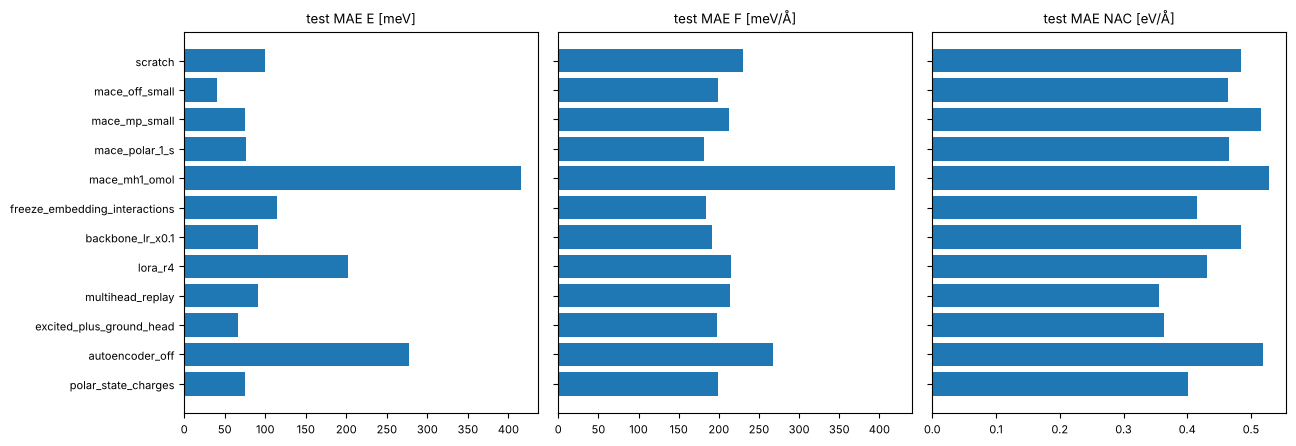

                           run  trainable  minutes
                       scratch     142992      7.2
                mace_off_small     380784      1.8
                 mace_mp_small     463504     21.6
                mace_polar_1_s    7972094      5.8
                 mace_mh1_omol    6382486     11.5
 freeze_embedding_interactions     129712      1.7
              backbone_lr_x0.1     380784      1.8
                       lora_r4     115600      1.9
              multihead_replay     382672      4.6
      excited_plus_ground_head     382672      4.3
               autoencoder_off     437884      1.9
           polar_state_charges    7976814      5.3


In [10]:
names = list(RESULTS)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, key, unit in zip(axes, ("E", "F", "NAC"), ("meV", "meV/Å", "eV/Å")):
    ax.barh(names, [RESULTS[n][key] for n in names], color="tab:blue")
    ax.set(title=f"test MAE {key} [{unit}]")
    ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
plt.tight_layout()
plt.show()
print(f"{'run':>30} {'trainable':>10} {'minutes':>8}")
for n in names:
    print(f"{n:>30} {RESULTS[n]['trainable']:>10} {RESULTS[n]['minutes']:>8.1f}")

How to choose:

* **Little data, similar chemistry to the foundation:** full fine-tuning with a
  smaller backbone learning rate, or LoRA. Watch the validation error of the
  *energies and forces*: if they get worse while the couplings improve, the backbone
  is being pulled away — freeze more or use replay.
* **You need the ground state to stay good** (e.g. dynamics that leave the excited
  states, or a ground-state head for MD): multi-head fine-tuning with replay.
* **More data:** full fine-tuning; with enough data, starting from scratch catches
  up, but a foundation still converges faster.
* **Charge-transfer states:** MACE-POLAR-1 with `--excited_long_range=state`.

In this run, multi-head replay and the extra ground-state head gave the best
couplings of all OFF-based runs: training on more geometries (even ground-state
only) shapes the shared backbone features that the couplings are read from. The
numbers come from 15 epochs on 120 frames of an LVC model, so the ranking is only a
guide; rerun the comparison on your own data.

## 5. Fine-tuning a fine-tuned model on additional data

Say the MACE-OFF model from section 3 is in production, and new reference
calculations arrive (`extra.xyz`, 240 frames). Pass the **trained X-MACE model** as
`--foundation_model`. X-MACE recognises an excited-state model and then:

* **continues** — when this run's heads have the states and couplings of the model's
  heads (same name, or chosen with `--foundation_head`) and the same model class:
  all weights are kept (backbone, adapter, every readout, shifts and scales) and
  training simply goes on with the new data;
* **transfers** — otherwise (different states, couplings or class): the backbone and
  adapter keep their weights, the state readouts are new.

Typically you continue on new *and* old data with a smaller learning rate, so the
model does not forget what it learned:

In [11]:
ase.io.write(RUN / "small_plus_extra.xyz", small + extra)
before = RESULTS["mace_off_small"]
after = train("continued", f"--foundation_model={RUN / 'mace_off_small' / 'mace_off_small.model'}",
              "--E0s=average", "--lr=0.001", train_file="small_plus_extra.xyz", epochs=10)
print(open(next((RUN / "continued" / "logs").glob("*run-1.log"))).read().split("Continuing")[1][:160])
print(f"energy MAE {before['E']:.1f} -> {after['E']:.1f} meV, forces {before['F']:.1f} -> "
      f"{after['F']:.1f} meV/Å, NACs {before['NAC']:.3f} -> {after['NAC']:.3f}")

             continued: E   39.0 meV | F  145.4 meV/Å | NAC 0.387 | SOC 7.75 | dip 0.0269 |   380784 trainable | 3.2 min
 from the excited-state foundation model: every head keeps all weights of its source head (Default <- Default), shifts and scales included
2026-11-09 14:46:07.3
energy MAE 39.9 -> 39.0 meV, forces 198.9 -> 145.4 meV/Å, NACs 0.465 -> 0.387


The log line says that every head continued from the trained model; the extra data
lowered the force and NAC errors further. Continuing works
with every option above: add `--lora=True` to update the backbone only in low rank,
`--freeze=N`, or a smaller `--lr`. Continuing also works for multi-head models (each
head continues from the head of the same name).

**Transfer to new states.** Suppose the new calculations only have the 4 singlets,
with NACs and dipoles (no triplets, no SOCs). The layout changes, so X-MACE
transfers: backbone and adapter from the trained model, new readouts.

In [12]:
singlets = []
for atoms in extra:
    a = atoms.copy()
    a.info = {
        "REF_energy": atoms.info["REF_energy"][:4],
        "REF_forces": atoms.info["REF_forces"][:, :4],
        "REF_nacs": atoms.info["REF_nacs"][:, :6],             # the 6 singlet pairs come first
        "REF_dipoles": np.concatenate([atoms.info["REF_dipoles"][:4], atoms.info["REF_dipoles"][7:13]]),
    }
    singlets.append(a)
ase.io.write(RUN / "singlets.xyz", singlets)

argv = ["mace_run_train", "--name=singlets", f"--work_dir={RUN / 'singlets'}",
        f"--train_file={RUN / 'singlets.xyz'}", "--max_num_epochs=10",
        f"--foundation_model={RUN / 'continued' / 'continued.model'}",
        "--model=ExcitedMACE", "--n_energies=4", "--compute_nacs", "--compute_dipoles",
        "--E0s=average", "--lora=True", "--lora_rank=4", *COMMON]
subprocess.run(argv, stdout=open(RUN / "singlets.out", "w"), stderr=subprocess.STDOUT, check=True)
log = open(next((RUN / "singlets" / "logs").glob("*run-1.log"))).read()
print(re.search(r"Transfer from[^\n]*", log).group(0)[:200])
calc = ExcitedMACECalculator(str(RUN / "singlets" / "singlets.model"))
print("singlet model:", calc.layout.states, "states,", len(calc.layout.nac_pairs), "NAC pairs")
mae = np.mean([np.abs(calc.predict(a)["energies"] - a.info["REF_energy"][:4]).mean() for a in test]) * 1000
print(f"test MAE of the 4 singlet energies: {mae:.1f} meV")

Transfer from the excited-state foundation model (the heads differ from the foundation's (states, couplings or names)): backbone and adapter layer keep their weights, the readouts of the heads Default
singlet model: [4] states, 6 NAC pairs


test MAE of the 4 singlet energies: 26.8 meV


## Summary

* `--foundation_model` turns any ground-state MACE foundation into the backbone of an
  excited-state model; every state starts on its ground-state surface.
* Fine-tuning strategies are the usual MACE ones (`--freeze`, `--lr_params_factors`,
  `--lora`, `--multiheads_finetuning` with replay and pseudolabels, extra heads);
  they act on the backbone, while the adapter and state readouts always train.
* A trained X-MACE model is itself a foundation: same heads → it continues with all
  its weights; new states or couplings → backbone and adapter are transferred.
* Multi-GPU training, foundation-scale data sets and the other options are in
  `XMACE.md`.